# Analisis Indeks Inflasi 150 Daerah di Indonesia (Januari sampai November 2025)

Notebook ini menganalisis pola indeks inflasi bulanan di tingkat kota dan kabupaten.

## Alur notebook

| No | Tahap | Isinya |
|---|---|---|
| 0 | Persiapan | Memanggil library |
| 1 | Memasukkan data | Membaca file Excel |
| 2 | EDA | Memeriksa data mentah, mencari masalah |
| 3 | Cleaning | Memperbaiki masalah yang ditemukan di EDA |
| 4 | Preparation | Menyusun tabel dan angka yang siap dianalisis |
| 5 | Visualization | Grafik dan temuan |
| 6 | Kesimpulan | Ringkasan, keterbatasan, langkah lanjut |

## Ringkasan

- Indeks nasional negatif pada Januari, Februari, Mei, dan Agustus. Indeks naik tajam pada Maret (1,65) dan April (1,17).
- Polanya serentak. Pada Januari, Februari, dan Mei, sedikitnya 125 dari 150 daerah mencatat indeks negatif. Pada Maret tidak ada satu pun.
- 117 dari 150 daerah mengikuti pola nasional (korelasi di atas 0,7). Hanya dua daerah berkorelasi negatif: Kab. Jayawijaya dan Kota Batam.
- Kabupaten lebih berfluktuasi daripada kota (rata-rata simpangan baku 0,93 lawan 0,78), padahal rata-rata indeksnya sama, sekitar 0,2.

## Pertanyaan

1. Bagaimana pola indeks nasional tiap bulan, dan kapan terjadi penurunan?
2. Seberapa serentak pola itu di daerah?
3. Daerah mana yang paling menyimpang dari pola nasional?
4. Daerah mana yang paling berfluktuasi?
5. Adakah nilai ekstrem, dan di mana?
6. Apakah kota dan kabupaten berbeda?

**Data:** file `InflasiUmum.xlsx` dengan kolom `periode`, `kota`, dan `index`. Sumber data: [isi sumber data].

## Cara membaca notebook ini

- **Kotak tulisan** (seperti ini) berisi penjelasan.
- **Kotak kode** berisi perintah Python. Tekan `Shift + Enter` untuk menjalankannya, atau pakai **Run All**. Jalankan dari atas ke bawah.
- Baris yang diawali `#` adalah komentar. Python tidak menjalankannya, isinya penjelasan kode.

**Istilah yang dipakai**

| Istilah | Artinya |
|---|---|
| Indeks | Angka inflasi satu daerah pada satu bulan |
| Rata-rata | Jumlah semua nilai dibagi banyaknya nilai |
| Median | Nilai tengah setelah semua nilai diurutkan |
| Simpangan baku | Ukuran seberapa jauh nilai menyebar. Makin besar, makin berfluktuasi |
| Korelasi | Ukuran apakah dua deret naik dan turun bersama. Dari -1 sampai 1. Dekat 1 berarti searah |
| Skor-z | Seberapa jauh satu nilai dari rata-rata kelompoknya, dalam satuan simpangan baku |
| Nilai ekstrem | Nilai yang sangat jauh dari yang lain. Di sini: skor-z di atas 3 atau di bawah -3 |

## 0. Persiapan

Kotak ini memanggil library. `pandas` untuk mengolah tabel, `matplotlib` untuk membuat grafik.

In [29]:
# Library untuk mengolah tabel data
import pandas as pd

# Library untuk membuat grafik
import matplotlib.pyplot as plt

# Menyembunyikan peringatan yang tidak penting
import warnings
warnings.filterwarnings("ignore")

# Ketajaman grafik
plt.rcParams["figure.dpi"] = 100

# Nama bulan untuk label grafik
peta_bulan = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "Mei", 6: "Jun",
    7: "Jul", 8: "Agu", 9: "Sep", 10: "Okt", 11: "Nov", 12: "Des",
}

# Fungsi untuk memendekkan nama daerah di grafik
# Contoh: "KAB GORONTALO" menjadi "Kab. GORONTALO"
def singkat(nama):
    nama = nama.replace("KAB ", "Kab. ")
    nama = nama.replace("KOTA ", "Kota ")
    return nama

## 1. Memasukkan data

Baca file Excel apa adanya. Belum ada yang diubah.

In [30]:
# Membaca file Excel
data_mentah = pd.read_excel("InflasiUmum.xlsx")

# Menampilkan ukuran dan lima baris pertama
print("Ukuran data (baris, kolom):", data_mentah.shape)
data_mentah.head()

Ukuran data (baris, kolom): (1672, 3)


,periode,kota,index
0,2025-01-01,KAB ACEH TENGAH,"0,27"
1,2025-02-01,KAB ACEH TENGAH,"-0,32"
2,2025-03-01,KAB ACEH TENGAH,"1,66"
3,2025-04-01,KAB ACEH TENGAH,"2,15"
4,2025-05-01,KAB ACEH TENGAH,"-0,49"


## 2. EDA (Exploratory Data Analysis)

Tujuan tahap ini: **mengenali data mentah dan mencari masalahnya**. Di sini belum ada yang diperbaiki. Perbaikan dilakukan di tahap 3.

**2.1 Struktur data:** nama kolom, tipe data, dan jumlah isi tiap kolom.

In [31]:
data_mentah.info()

<class 'pandas.DataFrame'>
RangeIndex: 1672 entries, 0 to 1671
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   periode  1672 non-null   datetime64[us]
 1   kota     1672 non-null   str           
 2   index    1672 non-null   object        
dtypes: datetime64[us](1), object(1), str(1)
memory usage: 59.7+ KB


**2.2 Isi data:** berapa nilai berbeda di tiap kolom.

In [32]:
print("Jumlah nama kota/daerah :", data_mentah["kota"].nunique())
print("Jumlah bulan            :", data_mentah["periode"].nunique())
print("Bulan paling awal       :", data_mentah["periode"].min())
print("Bulan paling akhir      :", data_mentah["periode"].max())

Jumlah nama kota/daerah : 152
Jumlah bulan            : 11
Bulan paling awal       : 2025-01-01 00:00:00
Bulan paling akhir      : 2025-11-01 00:00:00


**2.3 Baris dobel:** satu daerah seharusnya hanya muncul sekali per bulan.

In [33]:
print("Baris dobel:", data_mentah.duplicated(["kota", "periode"]).sum())

Baris dobel: 0


**2.4 Format angka.** Kolom `index` kemungkinan memakai koma sebagai pemisah desimal (misalnya `0,27`). Python butuh titik. Kita cek dulu seberapa banyak.

In [34]:
# Contoh isi kolom index
print(data_mentah["index"].head(10).tolist())

# Berapa nilai yang memakai koma?
jumlah_koma = data_mentah["index"].astype(str).str.contains(",").sum()
print("Nilai yang memakai koma:", jumlah_koma)

['0,27', '-0,32', '1,66', '2,15', '-0,49', '-0,35', '0,82', '1,4', '-0,14', '-0,18']
Nilai yang memakai koma: 1656


**2.5 Nilai kosong.** Untuk memeriksa, kita ubah sementara kolom `index` menjadi angka. Hasilnya belum disimpan ke data.

In [35]:
# Ubah sementara (hanya untuk pemeriksaan)
angka_sementara = pd.to_numeric(
    data_mentah["index"].astype(str).str.replace(",", "."),
    errors="coerce"
)

print("Jumlah nilai kosong:", angka_sementara.isna().sum())
print()
print("Daerah yang punya nilai kosong:")
print(data_mentah.loc[angka_sementara.isna(), "kota"].value_counts())

Jumlah nilai kosong: 11

Daerah yang punya nilai kosong:
kota
DILI    11
Name: count, dtype: int64


**2.6 Nama yang tidak biasa.** Ada baris bernama `INDONESIA`. Kita lihat isinya.

In [36]:
data_mentah[data_mentah["kota"] == "INDONESIA"].head(11)

,periode,kota,index
1661,2025-01-01,INDONESIA,"-0,76"
1662,2025-02-01,INDONESIA,"-0,48"
1663,2025-03-01,INDONESIA,"1,65"
1664,2025-04-01,INDONESIA,"1,17"
1665,2025-05-01,INDONESIA,"-0,37"
1666,2025-06-01,INDONESIA,"0,19"
1667,2025-07-01,INDONESIA,"0,3"
1668,2025-08-01,INDONESIA,"-0,08"
1669,2025-09-01,INDONESIA,"0,21"
1670,2025-10-01,INDONESIA,"0,28"


**Hasil EDA: tiga masalah yang harus diperbaiki di tahap Cleaning**

| No | Masalah | Perbaikan |
|---|---|---|
| 1 | Kolom `index` memakai koma desimal, tipenya bukan angka | Ganti koma dengan titik, ubah ke angka |
| 2 | **Dili** tidak punya satu pun data (semua 11 nilainya kosong) | Dibuang, bukan diisi, supaya tidak ada angka karangan |
| 3 | Ada baris **INDONESIA**. Itu angka nasional, bukan kota | Dipisahkan, dipakai sebagai pembanding |

## 3. Cleaning

Memperbaiki tiga masalah dari tahap EDA, satu per satu.

**3.1 Memilih kolom dan mengganti nama** supaya lebih mudah dibaca.

In [37]:
# Ambil tiga kolom yang dipakai, lalu ganti namanya
data = data_mentah[["periode", "kota", "index"]].copy()
data = data.rename(columns={"kota": "daerah", "index": "indeks"})

data.head()

,periode,daerah,indeks
0,2025-01-01,KAB ACEH TENGAH,"0,27"
1,2025-02-01,KAB ACEH TENGAH,"-0,32"
2,2025-03-01,KAB ACEH TENGAH,"1,66"
3,2025-04-01,KAB ACEH TENGAH,"2,15"
4,2025-05-01,KAB ACEH TENGAH,"-0,49"


**3.2 Masalah 1: memperbaiki tipe data.** Koma diganti titik, teks diubah menjadi angka, periode diubah menjadi tanggal.

In [38]:
# Ganti koma dengan titik
data["indeks"] = data["indeks"].astype(str).str.replace(",", ".")

# Ubah teks menjadi angka. Nilai yang gagal diubah menjadi kosong (NaN)
data["indeks"] = pd.to_numeric(data["indeks"], errors="coerce")

# Ubah periode menjadi tanggal
data["periode"] = pd.to_datetime(data["periode"])

data.dtypes

periode    datetime64[us]
daerah                str
indeks            float64
dtype: object

**3.3 Masalah 3: memisahkan angka nasional (INDONESIA).**

In [39]:
# Ambil baris INDONESIA, simpan sebagai deret per bulan
nasional = data[data["daerah"] == "INDONESIA"]
nasional = nasional.set_index("periode")["indeks"].sort_index()

nasional

periode
2025-01-01   -0.76
2025-02-01   -0.48
2025-03-01    1.65
2025-04-01    1.17
2025-05-01   -0.37
2025-06-01    0.19
2025-07-01    0.30
2025-08-01   -0.08
2025-09-01    0.21
2025-10-01    0.28
2025-11-01    0.17
Name: indeks, dtype: float64

**3.4 Masalah 2: membuang daerah tanpa data (DILI) dan baris INDONESIA** dari data daerah.

In [40]:
# Buang INDONESIA dan DILI
df = data[~data["daerah"].isin(["INDONESIA", "DILI"])].copy()

# Urutkan dan rapikan nomor baris
df = df.sort_values(["daerah", "periode"]).reset_index(drop=True)

df.head()

,periode,daerah,indeks
0,2025-01-01,BANYUWANGI,-0.04
1,2025-02-01,BANYUWANGI,-0.24
2,2025-03-01,BANYUWANGI,1.50
3,2025-04-01,BANYUWANGI,0.77
4,2025-05-01,BANYUWANGI,-0.68


**3.5 Memeriksa hasil cleaning.** Semua daerah harus punya 11 bulan, tanpa nilai kosong dan tanpa baris dobel.

In [41]:
n_daerah = df["daerah"].nunique()
bulan_per_daerah = df.groupby("daerah").size()

print("Jumlah daerah        :", n_daerah)
print("Jumlah bulan         :", df["periode"].nunique())
print("Jumlah baris         :", len(df))
print("Nilai kosong tersisa :", df["indeks"].isna().sum())
print("Baris dobel          :", df.duplicated(["daerah", "periode"]).sum())
print("Semua daerah punya 11 bulan:", (bulan_per_daerah == 11).all())

Jumlah daerah        : 150
Jumlah bulan         : 11
Jumlah baris         : 1650
Nilai kosong tersisa : 0
Baris dobel          : 0
Semua daerah punya 11 bulan: True


In [42]:
# Ringkasan statistik seluruh nilai indeks setelah dibersihkan
df["indeks"].describe().round(2)

count    1650.00
mean        0.21
std         0.85
min        -2.47
25%        -0.31
50%         0.14
75%         0.59
max         3.99
Name: indeks, dtype: float64

## 4. Preparation

Data sudah bersih. Sekarang kita **susun tabel dan hitung angka-angka** yang akan dipakai untuk grafik dan kesimpulan. Semua perhitungan ada di tahap ini, supaya tahap Visualization hanya berisi grafik.

**4.1 Tabel lebar.** Mengubah data menjadi baris = bulan, kolom = daerah. Bentuk ini memudahkan perhitungan per bulan dan per daerah.

In [43]:
tabel_lebar = df.pivot(index="periode", columns="daerah", values="indeks")

# Label bulan (Jan, Feb, ...) untuk sumbu grafik
label_bulan = [peta_bulan[tanggal.month] for tanggal in tabel_lebar.index]

tabel_lebar.iloc[:, :5]   # tampilkan 5 kolom pertama saja

daerah,BANYUWANGI,BULUKUMBA,BUNGO,CILACAP,DKI JAKARTA
periode,,,,,
2025-01-01,-0.04,-1.06,-0.47,-0.26,-1.50
2025-02-01,-0.24,-0.64,-0.42,-0.74,-0.29
2025-03-01,1.50,1.84,2.16,1.39,2.00
2025-04-01,0.77,1.73,1.79,1.04,1.44
2025-05-01,-0.68,-0.01,-0.77,-0.66,-0.24
2025-06-01,0.63,0.19,-0.17,0.43,0.13
2025-07-01,0.29,0.19,0.63,0.36,0.11
2025-08-01,-0.08,-0.03,0.40,-0.13,-0.05
2025-09-01,0.22,-0.04,0.55,0.34,0.13


**4.2 Tabel per bulan.** Rata-rata dan median semua daerah, jumlah daerah yang indeksnya negatif, lalu digabung dengan angka nasional.

In [44]:
# Tandai setiap baris: True kalau indeksnya negatif
df["negatif"] = df["indeks"] < 0

tabel_bulanan = pd.DataFrame({
    "nasional":         nasional,
    "rata_rata_daerah": df.groupby("periode")["indeks"].mean(),
    "median_daerah":    df.groupby("periode")["indeks"].median(),
    "daerah_negatif":   df.groupby("periode")["negatif"].sum(),   # jumlah True = jumlah daerah negatif
})

tabel_bulanan.round(2)

,nasional,rata_rata_daerah,median_daerah,daerah_negatif
periode,,,,
2025-01-01,-0.76,-0.65,-0.64,129
2025-02-01,-0.48,-0.40,-0.46,125
2025-03-01,1.65,1.73,1.69,0
2025-04-01,1.17,1.06,1.09,5
2025-05-01,-0.37,-0.40,-0.38,136
2025-06-01,0.19,0.16,0.17,44
2025-07-01,0.30,0.51,0.42,9
2025-08-01,-0.08,-0.11,-0.12,99
2025-09-01,0.21,0.19,0.17,42


In [45]:
# Selisih angka nasional dan rata-rata daerah
selisih = (tabel_bulanan["rata_rata_daerah"] - tabel_bulanan["nasional"]).abs()
print("Selisih terbesar antara angka nasional dan rata-rata daerah:", round(selisih.max(), 2), "poin")

# Perbedaan antar bulan vs perbedaan antar daerah
selisih_bulan = nasional.max() - nasional.min()
print("Selisih indeks nasional antar bulan (tertinggi - terendah):", round(selisih_bulan, 2), "poin")

Selisih terbesar antara angka nasional dan rata-rata daerah: 0.21 poin
Selisih indeks nasional antar bulan (tertinggi - terendah): 2.41 poin


**4.3 Tabel per daerah.** Satu baris untuk satu daerah, berisi semua ukuran yang kita butuhkan:

- `rata_rata`, `simpangan` (fluktuasi), `jumlah`: dari 11 bulan
- `korelasi`: seberapa searah dengan angka nasional
- `penyimpangan`: rata-rata selisih mutlak dengan angka nasional
- `jenis`: Kota, Kabupaten, atau Lainnya (dari awalan nama)

In [46]:
# Fungsi untuk menentukan jenis daerah dari awalan namanya
def tentukan_jenis(nama):
    if nama.startswith("KAB "):
        return "Kabupaten"
    elif nama.startswith("KOTA "):
        return "Kota"
    else:
        return "Lainnya"

# Rata-rata, simpangan baku, dan jumlah indeks 11 bulan untuk tiap daerah
tabel_daerah = df.groupby("daerah")["indeks"].agg(
    rata_rata="mean",
    simpangan="std",
    jumlah="sum",
)

# Korelasi tiap daerah dengan angka nasional
tabel_daerah["korelasi"] = tabel_lebar.corrwith(nasional)

# Rata-rata selisih mutlak tiap daerah dengan angka nasional
selisih_per_bulan = tabel_lebar.sub(nasional, axis=0)
tabel_daerah["penyimpangan"] = selisih_per_bulan.abs().mean()

# Jenis daerah (juga ditambahkan ke data utama)
tabel_daerah["jenis"] = tabel_daerah.index.map(tentukan_jenis)
df["jenis"] = df["daerah"].map(tentukan_jenis)

tabel_daerah.round(2).head()

,rata_rata,simpangan,jumlah,korelasi,penyimpangan,jenis
daerah,,,,,,
BANYUWANGI,0.24,0.58,2.66,0.89,0.22,Lainnya
BULUKUMBA,0.22,0.87,2.44,0.97,0.20,Lainnya
BUNGO,0.37,0.92,4.04,0.94,0.34,Lainnya
CILACAP,0.20,0.65,2.24,0.94,0.18,Lainnya
DKI JAKARTA,0.21,0.91,2.31,0.97,0.20,Lainnya


**4.4 Pembanding antar daerah.** Selisih rata-rata antar daerah dibandingkan dengan selisih antar bulan (dari 4.2).

In [47]:
selisih_daerah = tabel_daerah["rata_rata"].max() - tabel_daerah["rata_rata"].min()

print("Selisih indeks nasional antar bulan (tertinggi - terendah):", round(selisih_bulan, 2), "poin")
print("Selisih rata-rata antar daerah (tertinggi - terendah)     :", round(selisih_daerah, 2), "poin")
print()
print("Simpangan baku median seluruh daerah:", round(tabel_daerah["simpangan"].median(), 2))
print("Simpangan baku indeks nasional      :", round(nasional.std(), 2))
print("Jumlah indeks nasional 11 bulan     :", round(nasional.sum(), 2))

Selisih indeks nasional antar bulan (tertinggi - terendah): 2.41 poin
Selisih rata-rata antar daerah (tertinggi - terendah)     : 0.65 poin

Simpangan baku median seluruh daerah: 0.84
Simpangan baku indeks nasional      : 0.7
Jumlah indeks nasional 11 bulan     : 2.28


Perbedaan antar bulan jauh lebih besar daripada perbedaan antar daerah. **Waktu lebih menentukan nilai indeks daripada lokasi.**

**4.5 Peringkat daerah.** Lima teratas untuk tiap ukuran.

In [48]:
print("Rata-rata indeks tertinggi")
print(tabel_daerah.sort_values("rata_rata", ascending=False).head(5)[["rata_rata", "simpangan", "jumlah"]].round(2))

print()
print("Rata-rata indeks terendah")
print(tabel_daerah.sort_values("rata_rata").head(5)[["rata_rata", "simpangan", "jumlah"]].round(2))

print()
print("Paling berfluktuasi (simpangan baku tertinggi)")
print(tabel_daerah.sort_values("simpangan", ascending=False).head(5)[["rata_rata", "simpangan"]].round(2))

print()
print("Paling stabil (simpangan baku terendah)")
print(tabel_daerah.sort_values("simpangan").head(5)[["rata_rata", "simpangan"]].round(2))

Rata-rata indeks tertinggi
                   rata_rata  simpangan  jumlah
daerah                                         
KAB TOLI TOLI           0.61       1.56    6.68
TEMBILAHAN              0.46       0.98    5.09
KAB KERINCI             0.44       0.90    4.83
KAB PASAMAN BARAT       0.41       1.20    4.50
BUNGO                   0.37       0.92    4.04

Rata-rata indeks terendah
                      rata_rata  simpangan  jumlah
daerah                                            
KAB MINAHASA SELATAN      -0.05       1.35   -0.50
KAB MINAHASA UTARA        -0.03       1.16   -0.30
MAUMERE                   -0.03       0.89   -0.30
KAB HALMAHERA TENGAH      -0.01       1.12   -0.15
KOTA BANDAR LAMPUNG        0.00       0.94    0.05

Paling berfluktuasi (simpangan baku tertinggi)
                      rata_rata  simpangan
daerah                                    
KAB GORONTALO              0.15       1.67
KAB TOLI TOLI              0.61       1.56
KAB NABIRE                 0.36  

**4.6 Korelasi dan penyimpangan.** Ringkasan seberapa serentak daerah dengan pola nasional.

In [49]:
korelasi = tabel_daerah["korelasi"].sort_values()

print("Median korelasi              :", round(korelasi.median(), 2))
print("Daerah dengan korelasi > 0,7 :", (korelasi > 0.7).sum(), "dari", n_daerah)
print("Daerah dengan korelasi < 0,3 :", (korelasi < 0.3).sum(), "dari", n_daerah)
print("Daerah dengan korelasi < 0   :", (korelasi < 0).sum(), "dari", n_daerah)

print()
print("Lima daerah dengan korelasi terendah")
print(tabel_daerah.loc[korelasi.head(5).index, ["korelasi", "simpangan"]].round(2))

print()
print("Median penyimpangan seluruh daerah:", round(tabel_daerah["penyimpangan"].median(), 2), "poin")
print()
print("Sepuluh daerah paling menyimpang")
print(tabel_daerah.sort_values("penyimpangan", ascending=False).head(10)[["penyimpangan"]].round(2))

Median korelasi              : 0.89
Daerah dengan korelasi > 0,7 : 117 dari 150
Daerah dengan korelasi < 0,3 : 7 dari 150
Daerah dengan korelasi < 0   : 2 dari 150

Lima daerah dengan korelasi terendah
                          korelasi  simpangan
daerah                                       
KAB JAYAWIJAYA               -0.36       1.27
KOTA BATAM                   -0.04       0.34
KAB MALUKU TENGAH             0.01       1.06
KAB TIMOR TENGAH SELATAN      0.12       0.71
KAB KARO                      0.23       0.84

Median penyimpangan seluruh daerah: 0.34 poin

Sepuluh daerah paling menyimpang
                          penyimpangan
daerah                                
KAB JAYAWIJAYA                    1.37
KAB MALUKU TENGAH                 0.97
KAB PASAMAN BARAT                 0.95
KAB GORONTALO                     0.89
KAB KONAWE                        0.88
KAB TOLI TOLI                     0.86
KAB TIMOR TENGAH SELATAN          0.83
KAB NABIRE                        0.82
KAB M

**4.7 Nilai ekstrem.** Skor-z dihitung dengan rumus `(nilai - rata-rata bulan itu) / simpangan baku bulan itu`. Nilai dengan skor-z di atas 3 atau di bawah -3 ditandai ekstrem.

In [50]:
# Rata-rata dan simpangan baku tiap bulan, diisi ke setiap baris
rata_bulan = df.groupby("periode")["indeks"].transform("mean")
simpangan_bulan = df.groupby("periode")["indeks"].transform("std")

# Rumus skor-z
df["skor_z"] = (df["indeks"] - rata_bulan) / simpangan_bulan

# Ambil nilai ekstrem, urutkan dari yang paling jauh (tanpa melihat tanda plus/minus)
ekstrem = df[df["skor_z"].abs() > 3].copy()
ekstrem["skor_z_mutlak"] = ekstrem["skor_z"].abs()
ekstrem = ekstrem.sort_values("skor_z_mutlak", ascending=False)
ekstrem["bulan"] = ekstrem["periode"].dt.month.map(peta_bulan)

persen = len(ekstrem) / len(df) * 100
print("Nilai ekstrem:", len(ekstrem), "dari", len(df), "pengamatan (" + str(round(persen, 1)) + "%)")
print()
print("10 nilai paling ekstrem")
print(ekstrem[["daerah", "bulan", "indeks", "skor_z"]].head(10).round(2).to_string(index=False))

Nilai ekstrem: 20 dari 1650 pengamatan (1.2%)

10 nilai paling ekstrem
           daerah bulan  indeks  skor_z
   KAB JAYAWIJAYA   Feb    2.78    6.23
KAB MALUKU TENGAH   Apr   -1.67   -4.68
    KAB GORONTALO   Mei   -2.47   -4.31
KAB PASAMAN BARAT   Mei   -2.43   -4.23
    TANJUNG SELOR   Jul    2.33    4.01
KAB MALUKU TENGAH   Jun    1.89    3.95
        KOTA TUAL   Mei    1.48    3.92
   KAB JAYAWIJAYA   Jun   -1.50   -3.81
          MAUMERE   Okt   -1.29   -3.68
    KAB TOLI TOLI   Mar    3.99    3.45


In [51]:
# Nilai tertinggi dan terendah dari seluruh data
baris_tertinggi = df.loc[df["indeks"].idxmax()]
baris_terendah = df.loc[df["indeks"].idxmin()]

print("Tertinggi:", baris_tertinggi["daerah"], peta_bulan[baris_tertinggi["periode"].month], baris_tertinggi["indeks"])
print("Terendah :", baris_terendah["daerah"], peta_bulan[baris_terendah["periode"].month], baris_terendah["indeks"])

# Selisih nilai tertinggi dan terendah antar daerah di setiap bulan
rentang = tabel_lebar.max(axis=1) - tabel_lebar.min(axis=1)
bulan_lebar = rentang.idxmax()
print("Sebaran antar daerah paling lebar:", peta_bulan[bulan_lebar.month], "- selisih", round(rentang.max(), 2), "poin")

Tertinggi: KAB TOLI TOLI Mar 3.99
Terendah : KAB GORONTALO Mei -2.47
Sebaran antar daerah paling lebar: Agu - selisih 4.55 poin


**4.8 Kota dan kabupaten.** Ringkasan per jenis daerah.

In [52]:
kelompok = tabel_daerah.groupby("jenis")

ringkas = pd.DataFrame({
    "jumlah_daerah":       kelompok["rata_rata"].count(),
    "rata_rata_indeks":    kelompok["rata_rata"].mean(),
    "rata_rata_fluktuasi": kelompok["simpangan"].mean(),
    "median_fluktuasi":    kelompok["simpangan"].median(),
})
print(ringkas.round(2))

# Dari 10 daerah paling berfluktuasi, berapa kota/kabupaten?
sepuluh_berfluktuasi = tabel_daerah.sort_values("simpangan", ascending=False).head(10)
print()
print("Dari 10 daerah paling berfluktuasi:")
print(sepuluh_berfluktuasi["jenis"].value_counts())

# Rata-rata indeks tiap bulan menurut jenis daerah
rata_jenis = df.groupby(["periode", "jenis"])["indeks"].mean().unstack().round(2)
rata_jenis.index = label_bulan
print()
print("Rata-rata indeks tiap bulan menurut jenis daerah")
print(rata_jenis)

           jumlah_daerah  rata_rata_indeks  rata_rata_fluktuasi  \
jenis                                                             
Kabupaten             60              0.20                 0.93   
Kota                  65              0.22                 0.78   
Lainnya               25              0.21                 0.88   

           median_fluktuasi  
jenis                        
Kabupaten              0.91  
Kota                   0.76  
Lainnya                0.89  

Dari 10 daerah paling berfluktuasi:
jenis
Kabupaten    7
Lainnya      2
Kota         1
Name: count, dtype: int64

Rata-rata indeks tiap bulan menurut jenis daerah
jenis  Kabupaten  Kota  Lainnya
Jan        -0.47 -0.71    -0.92
Feb        -0.39 -0.44    -0.34
Mar         1.81  1.58     1.90
Apr         1.01  1.14     0.95
Mei        -0.54 -0.31    -0.32
Jun         0.09  0.21     0.21
Jul         0.58  0.40     0.60
Agu        -0.14 -0.05    -0.23
Sep         0.15  0.26     0.10
Okt         0.08  0.18     0.2

## 5. Visualization

Semua angka sudah siap dari tahap 4. Bagian ini hanya membuat grafik, masing-masing diikuti temuannya.

### 5.1 Pola nasional per bulan

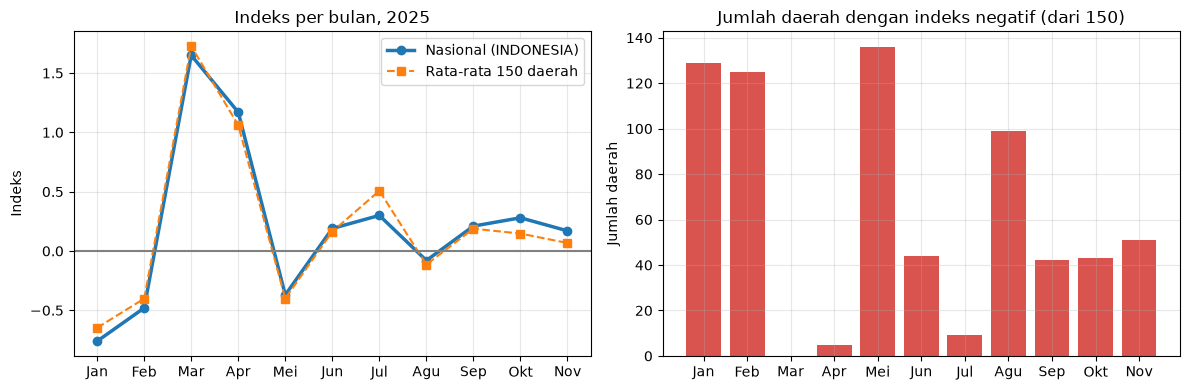

In [53]:
plt.figure(figsize=(12, 4))

# Grafik kiri: garis indeks nasional dan rata-rata daerah
plt.subplot(1, 2, 1)
plt.plot(label_bulan, tabel_bulanan["nasional"], marker="o", linewidth=2.5, label="Nasional (INDONESIA)")
plt.plot(label_bulan, tabel_bulanan["rata_rata_daerah"], marker="s", linestyle="--", label="Rata-rata " + str(n_daerah) + " daerah")
plt.axhline(0, color="gray")
plt.title("Indeks per bulan, 2025")
plt.ylabel("Indeks")
plt.legend()
plt.grid(alpha=0.3)

# Grafik kanan: batang jumlah daerah dengan indeks negatif
plt.subplot(1, 2, 2)
plt.bar(label_bulan, tabel_bulanan["daerah_negatif"], color="#d9534f")
plt.title("Jumlah daerah dengan indeks negatif (dari " + str(n_daerah) + ")")
plt.ylabel("Jumlah daerah")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Temuan**

- Indeks nasional negatif pada empat bulan: Januari (-0,76), Februari (-0,48), Mei (-0,37), dan Agustus (-0,08).
- Indeks tertinggi terjadi pada Maret (1,65), lalu April (1,17).
- Pada Januari, Februari, dan Mei, 129, 125, dan 136 dari 150 daerah mencatat indeks negatif. Pada Maret, tidak ada satu pun.
- Rata-rata sederhana 150 daerah mengikuti angka nasional dengan selisih kecil. Selisih terbesar 0,21 poin, pada Juli.
- Data menunjukkan polanya, bukan penyebabnya. Penyebab perlu diperiksa dengan sumber lain.

### 5.2 Seberapa serentak pola di daerah?

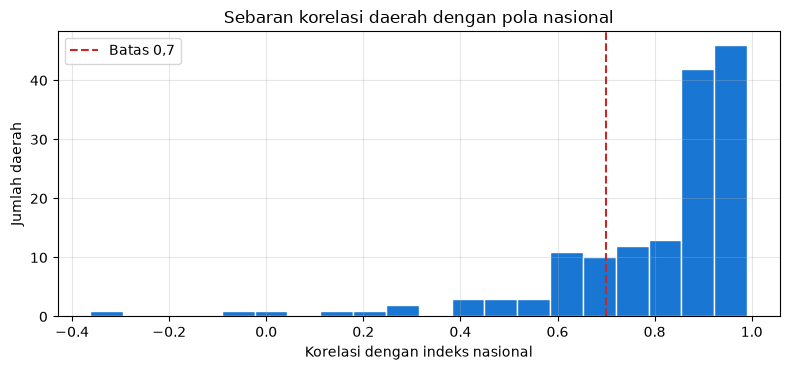

In [54]:
plt.figure(figsize=(8, 3.8))
plt.hist(tabel_daerah["korelasi"], bins=20, color="#1976d2", edgecolor="white")
plt.axvline(0.7, color="#c62828", linestyle="--", label="Batas 0,7")
plt.xlabel("Korelasi dengan indeks nasional")
plt.ylabel("Jumlah daerah")
plt.title("Sebaran korelasi daerah dengan pola nasional")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Catatan: tiap daerah hanya punya 11 titik, jadi korelasi ini ukuran kasar.

**Temuan**

- Sebagian besar daerah bergerak searah dengan nasional. Median korelasi 0,89, dan 117 dari 150 daerah punya korelasi di atas 0,7.
- Hanya dua daerah berkorelasi negatif: Kab. Jayawijaya (-0,36) dan Kota Batam (-0,04). Kab. Maluku Tengah (0,01) hampir tidak berkorelasi.
- Batam punya fluktuasi terkecil dari semua daerah (simpangan baku 0,34, nasional 0,70). Ia tidak ikut berayun sebesar pola nasional.

### 5.3 Daerah yang paling menyimpang dari angka nasional

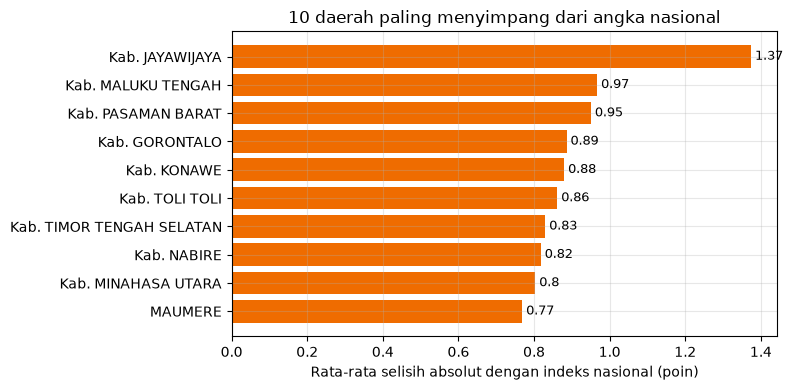

In [55]:
# Ambil 10 daerah dengan penyimpangan terbesar
sepuluh_teratas = tabel_daerah["penyimpangan"].sort_values(ascending=False).head(10)
nama_pendek = [singkat(nama) for nama in sepuluh_teratas.index]

plt.figure(figsize=(8, 4))
plt.barh(nama_pendek, sepuluh_teratas.values, color="#ef6c00")
plt.gca().invert_yaxis()   # supaya yang terbesar ada di atas

# Tulis angka di ujung setiap batang
for i, nilai in enumerate(sepuluh_teratas.values):
    plt.text(nilai + 0.01, i, str(round(nilai, 2)), va="center", fontsize=9)

plt.xlabel("Rata-rata selisih absolut dengan indeks nasional (poin)")
plt.title("10 daerah paling menyimpang dari angka nasional")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Temuan**

- Kab. Jayawijaya paling menyimpang (1,37 poin), sekitar empat kali nilai median seluruh daerah (0,34).
- Disusul Kab. Maluku Tengah (0,97), Kab. Pasaman Barat (0,95), dan Kab. Gorontalo (0,89).
- Daerah-daerah ini perlu dicek lebih lanjut kalau data dipakai untuk pemantauan.

### 5.4 Rata-rata dan fluktuasi tiap daerah

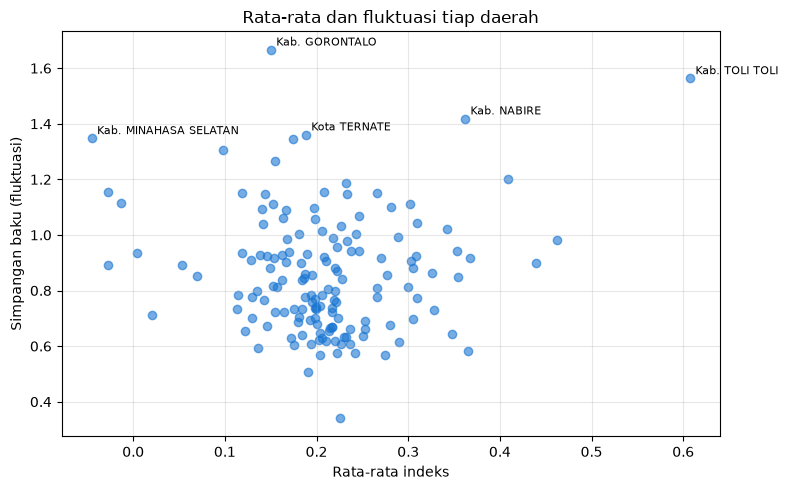

In [56]:
plt.figure(figsize=(8, 5))
plt.scatter(tabel_daerah["rata_rata"], tabel_daerah["simpangan"], alpha=0.6, color="#1976d2")

# Beri nama pada 5 daerah paling berfluktuasi
lima_terbesar = tabel_daerah.sort_values("simpangan", ascending=False).head(5)
for nama in lima_terbesar.index:
    x = lima_terbesar.loc[nama, "rata_rata"]
    y = lima_terbesar.loc[nama, "simpangan"]
    plt.annotate(singkat(nama), (x, y), fontsize=8, xytext=(4, 3), textcoords="offset points")

plt.xlabel("Rata-rata indeks")
plt.ylabel("Simpangan baku (fluktuasi)")
plt.title("Rata-rata dan fluktuasi tiap daerah")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Temuan**

- Rata-rata indeks tertinggi: Kab. Toli-Toli (0,61), Tembilahan (0,46), dan Kab. Kerinci (0,44). Jumlah indeks Toli-Toli 11 bulan (6,68) hampir tiga kali angka nasional (2,28). Jumlah ini memakai asumsi indeks adalah perubahan bulanan.
- Rata-rata terendah: Kab. Minahasa Selatan (-0,05) dan Kab. Minahasa Utara (-0,03).
- Paling berfluktuasi: Kab. Gorontalo (1,67), Kab. Toli-Toli (1,56), dan Kab. Nabire (1,42). Nilai ini jauh di atas median daerah (0,84).
- Paling stabil: Kota Batam (0,34).
- Selisih rata-rata antar daerah kecil (0,65 poin). Perbedaan terbesar antar daerah ada pada tingkat fluktuasinya, bukan pada rata-ratanya.

### 5.5 Peta panas: 15 daerah paling berfluktuasi

Setiap sel menunjukkan indeks satu daerah pada satu bulan. Merah berarti indeks tinggi, biru berarti negatif.

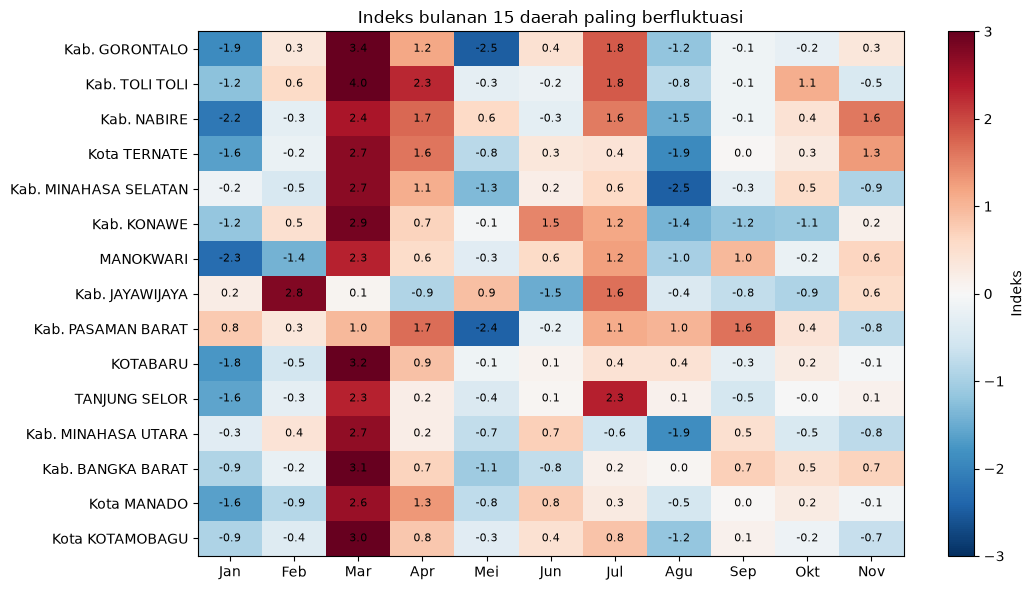

In [57]:
# Ambil 15 daerah dengan simpangan baku terbesar, lalu putar tabel (.T)
# supaya baris = daerah dan kolom = bulan
nama_15 = tabel_daerah.sort_values("simpangan", ascending=False).head(15).index
peta = tabel_lebar[nama_15].T
nama_pendek_15 = [singkat(nama) for nama in peta.index]

plt.figure(figsize=(11, 6))
plt.imshow(peta.values, cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
plt.colorbar(label="Indeks")
plt.xticks(range(11), label_bulan)
plt.yticks(range(15), nama_pendek_15)
plt.grid(False)

# Tulis angka di setiap kotak
for baris in range(15):
    for kolom in range(11):
        plt.text(kolom, baris, str(round(peta.values[baris, kolom], 1)), ha="center", va="center", fontsize=8)

plt.title("Indeks bulanan 15 daerah paling berfluktuasi")
plt.tight_layout()
plt.show()

**Temuan**

- Hampir semua daerah dalam peta ini memerah pada Maret. Itu sama dengan lonjakan nasional.
- Ada juga lonjakan dan penurunan lokal di luar pola nasional. Contohnya Kab. Jayawijaya pada Februari (2,8), serta Kab. Gorontalo dan Kab. Pasaman Barat pada Mei (sekitar -2,5).
- Fluktuasi besar di daerah ini datang dari beberapa nilai tajam, bukan dari gerak kecil yang terus-menerus.

### 5.6 Nilai ekstrem: sebaran antar daerah per bulan

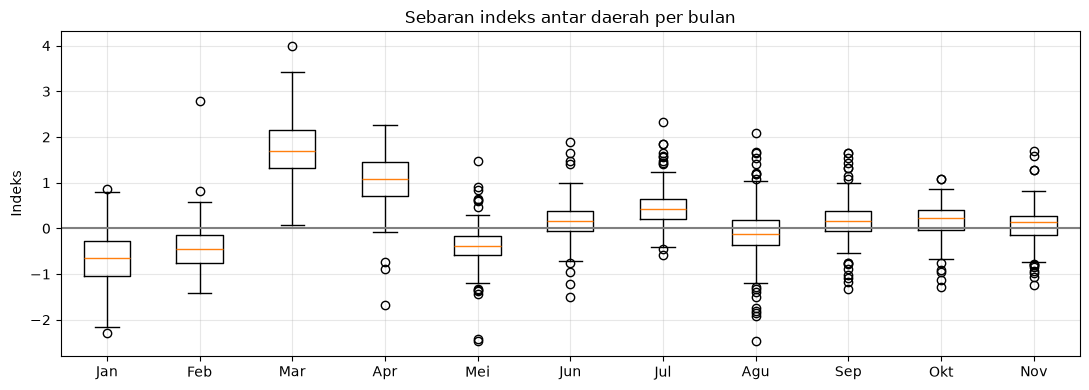

In [58]:
# Diagram kotak: sebaran indeks semua daerah di setiap bulan
data_per_bulan = [tabel_lebar.loc[tanggal] for tanggal in tabel_lebar.index]

plt.figure(figsize=(11, 4))
plt.boxplot(data_per_bulan)
plt.xticks(range(1, 12), label_bulan)
plt.axhline(0, color="gray")
plt.ylabel("Indeks")
plt.title("Sebaran indeks antar daerah per bulan")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Temuan**

- Nilai ekstrem jarang: 20 dari 1.650 pengamatan (1,2%).
- Yang paling ekstrem: Kab. Jayawijaya pada Februari (2,78, skor-z sekitar 6,2). Nilai itu jauh di atas daerah lain pada bulan yang sama.
- Nilai tertinggi: Kab. Toli-Toli pada Maret (3,99). Nilai terendah: Kab. Gorontalo pada Mei (-2,47).
- Sebaran antar daerah paling lebar pada Agustus. Selisih nilai tertinggi dan terendah mencapai 4,55 poin.
- Nilai ekstrem bisa berasal dari kejadian lokal atau kesalahan pencatatan. Datanya sendiri tidak bisa membedakan keduanya, jadi perlu dicek ke sumber.

### 5.7 Kota dan kabupaten

Pengelompokan hanya dari awalan nama: `KOTA`, `KAB`, dan sisanya "Lainnya" (nama tanpa awalan, seperti Cilacap dan Maumere). Kelompok "Lainnya" tidak pasti.

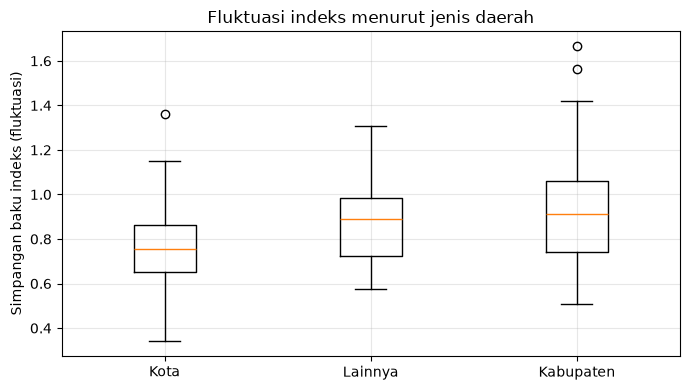

In [59]:
urutan = ["Kota", "Lainnya", "Kabupaten"]
data_jenis = [tabel_daerah.loc[tabel_daerah["jenis"] == jenis, "simpangan"] for jenis in urutan]

plt.figure(figsize=(7, 4))
plt.boxplot(data_jenis)
plt.xticks([1, 2, 3], urutan)
plt.ylabel("Simpangan baku indeks (fluktuasi)")
plt.title("Fluktuasi indeks menurut jenis daerah")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Temuan**

- Rata-rata indeks ketiga kelompok hampir sama (sekitar 0,2). Yang berbeda adalah fluktuasinya.
- Kabupaten paling berfluktuasi (rata-rata simpangan baku 0,93). Kota paling stabil (0,78).
- Tujuh dari sepuluh daerah paling berfluktuasi adalah kabupaten, padahal kabupaten hanya 40% dari seluruh daerah (60 dari 150).
- Pada bulan penurunan, kota turun lebih dalam di Januari (-0,71 lawan -0,47), sedangkan kabupaten turun lebih dalam di Mei (-0,54 lawan -0,31).
- Data ini belum menjelaskan sebabnya. Sebab yang masuk akal (misalnya struktur pasar atau ukuran daerah) perlu diuji dengan data tambahan.

## 6. Kesimpulan

1. **Waktu lebih menentukan daripada lokasi.** Indeks nasional berayun 2,41 poin antar bulan, sedangkan rata-rata antar daerah hanya berbeda 0,65 poin.
2. **Polanya serentak.** Empat bulan negatif pada tingkat nasional. Pada tiga di antaranya, sedikitnya 125 daerah ikut negatif. Pada Maret, tidak ada satu pun.
3. **Sebagian kecil daerah bergerak sendiri.** 117 dari 150 daerah mengikuti pola nasional. Kab. Jayawijaya menyimpang paling jauh, dan Kota Batam bergerak paling kecil dibanding daerah lain.
4. **Fluktuasi lebih tinggi di kabupaten.** Perbedaan kota dan kabupaten ada di fluktuasi, bukan di rata-rata.
5. **Nilai ekstrem jarang tetapi nyata.** 20 dari 1.650 pengamatan, dengan Jayawijaya (Februari) sebagai yang paling ekstrem.

### Implikasi untuk pemantauan

- Daerah dengan fluktuasi tinggi dan korelasi rendah, seperti Jayawijaya dan Maluku Tengah, perlu dipantau lebih ketat daripada daerah lain.
- Daerah dengan fluktuasi tertinggi, seperti Gorontalo, Toli-Toli, dan Nabire, sulit dipantau dengan angka rata-rata. Nilai bulanannya perlu dilihat satu per satu.
- Nilai ekstrem perlu dicek ke sumber lapangan sebelum dipakai untuk kesimpulan.
- Karena pola nasional kuat, perubahan di tingkat nasional bisa dipakai sebagai peringatan dini untuk sebagian besar daerah.

### Keterbatasan

- Data hanya 11 bulan di tahun 2025, jadi pola musiman belum bisa dipastikan.
- Data tidak memuat kelompok pengeluaran (pangan, energi, dan lainnya), jadi penyebab pola tidak bisa diuji.
- Definisi "indeks" perlu dipastikan dari sumber data. Analisis ini menganggapnya perubahan bulanan.
- Pengelompokan kota dan kabupaten hanya dari nama daerah.
- Korelasi dihitung dari 11 titik, jadi hanya ukuran kasar.
- Analisis bersifat deskriptif. Tidak ada klaim sebab-akibat.

### Langkah lanjut

Tambah data beberapa tahun untuk melihat pola musiman, tambah data kelompok pengeluaran, dan tambah data provinsi untuk membandingkan wilayah.